# Detecting AI-generated video from its frequency content: live demo

IE 643, Astitva Garg (24B2440). Run the cells one at a time, top to bottom.

1. Show a real clip and a generated clip.
2. Extract their spectra live.
3. Trace one clip from frames to features to a verdict.
4. Compare **pixel-only**, **frequency-only** and **combined** features on the same held-out clips.
5. Check that every number matches the stored results.

All clips used here come from the **test split**: never used for training or for choosing a model.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from src.config import CLIPS, FPS, N_FRAMES, RESULTS, SEED, SEEN, UNSEEN
from src.data.video_io import read_frames
from src.features.spatial import power_spectrum, radial_spectrum, residual, to_luma, frame_features
from src.features.temporal import clip_features
from src.features.pixel_baseline import clip_pixel_features
from src.models import data as D
import src.demo_live as L        # only its small helpers: load_model, score, load_cnn, boot
# demo_live selects a file-only plotting backend; switch back so plots appear in the notebook
%matplotlib inline

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED = "#2a6f97", "#c9184a"
print("project root:", root)

project root: C:\ie643_project


## 1. Real and generated examples

Both clips are drawn from the held-out test split with a fixed random seed (not by hand).
To try another pair, set `REAL_ID` / `FAKE_ID` to any test `clip_id` (see the table below).

generator
modelscope     99
real           65
wan            57
ltx            17
svd            16
animatediff    13 

real  real_3121923  source=real  scene=river stream  split=test  frames=(14, 256, 256, 3)
AI    ltx_0001  source=ltx  scene=ocean waves  split=test  frames=(14, 256, 256, 3)


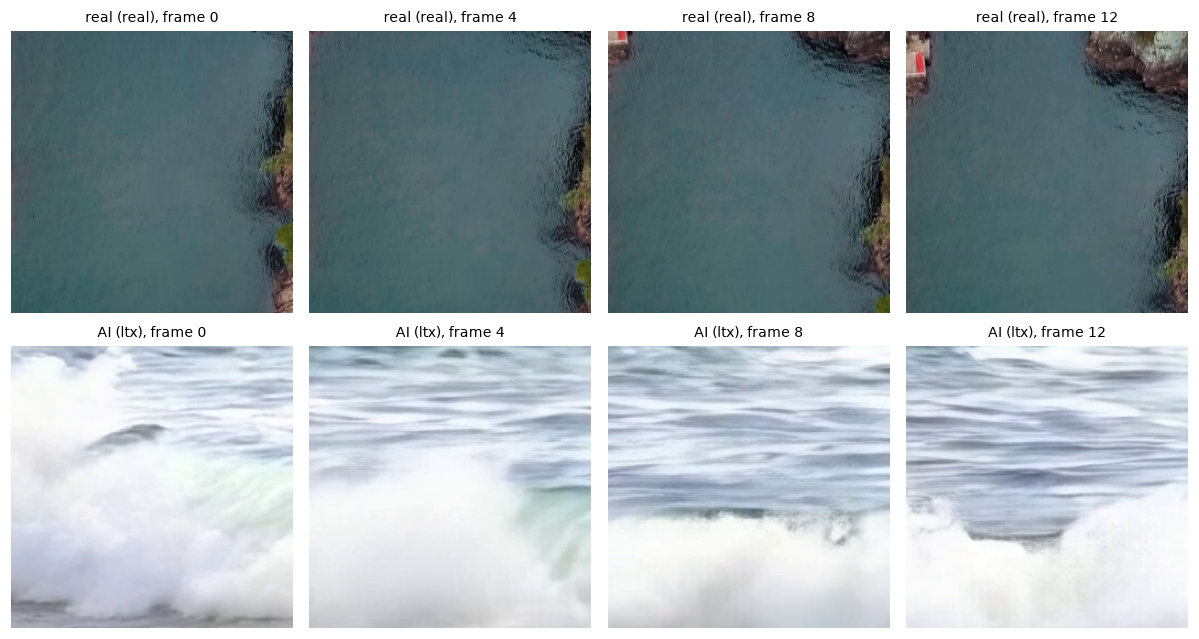

In [2]:
man = D.manifest()
test = man[(man.split == "test") & ~man.aug.astype(bool)]
print(test.generator.value_counts().to_string(), "\n")

REAL_ID, FAKE_ID = L.pick_examples(man)          # change these to try other clips
ids = {"real": REAL_ID, "AI": FAKE_ID}
frames = {}
fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for r, (tag, cid) in enumerate(ids.items()):
    row = man[man.clip_id == cid].iloc[0]
    frames[tag] = read_frames(CLIPS / f"{cid}.mp4", N_FRAMES, FPS)
    print(f"{tag:5s} {cid}  source={row.generator}  scene={row.scene}  split={row.split}  frames={frames[tag].shape}")
    for j, i in enumerate((0, 4, 8, 12)):
        ax[r, j].imshow(frames[tag][i]); ax[r, j].axis("off")
        ax[r, j].set_title(f"{tag} ({row.generator}), frame {i}", fontsize=9)
plt.tight_layout(); plt.show()

## 2. Spectra, extracted live

For one frame of each clip: grey-scale it, remove the mean, apply a Hann window, take the 2-D FFT and the log of its power.
The centre of the map is coarse structure and the edge is fine detail.
The **radial curve** averages the map over rings, giving one number per spatial-frequency bin (48 bins).
The **noise residual** is the frame minus its 3x3 median, which keeps only the fine texture.

real  spectral slope -2.14   energy beyond 75% of Nyquist 0.0048
AI    spectral slope -3.75   energy beyond 75% of Nyquist 0.0004


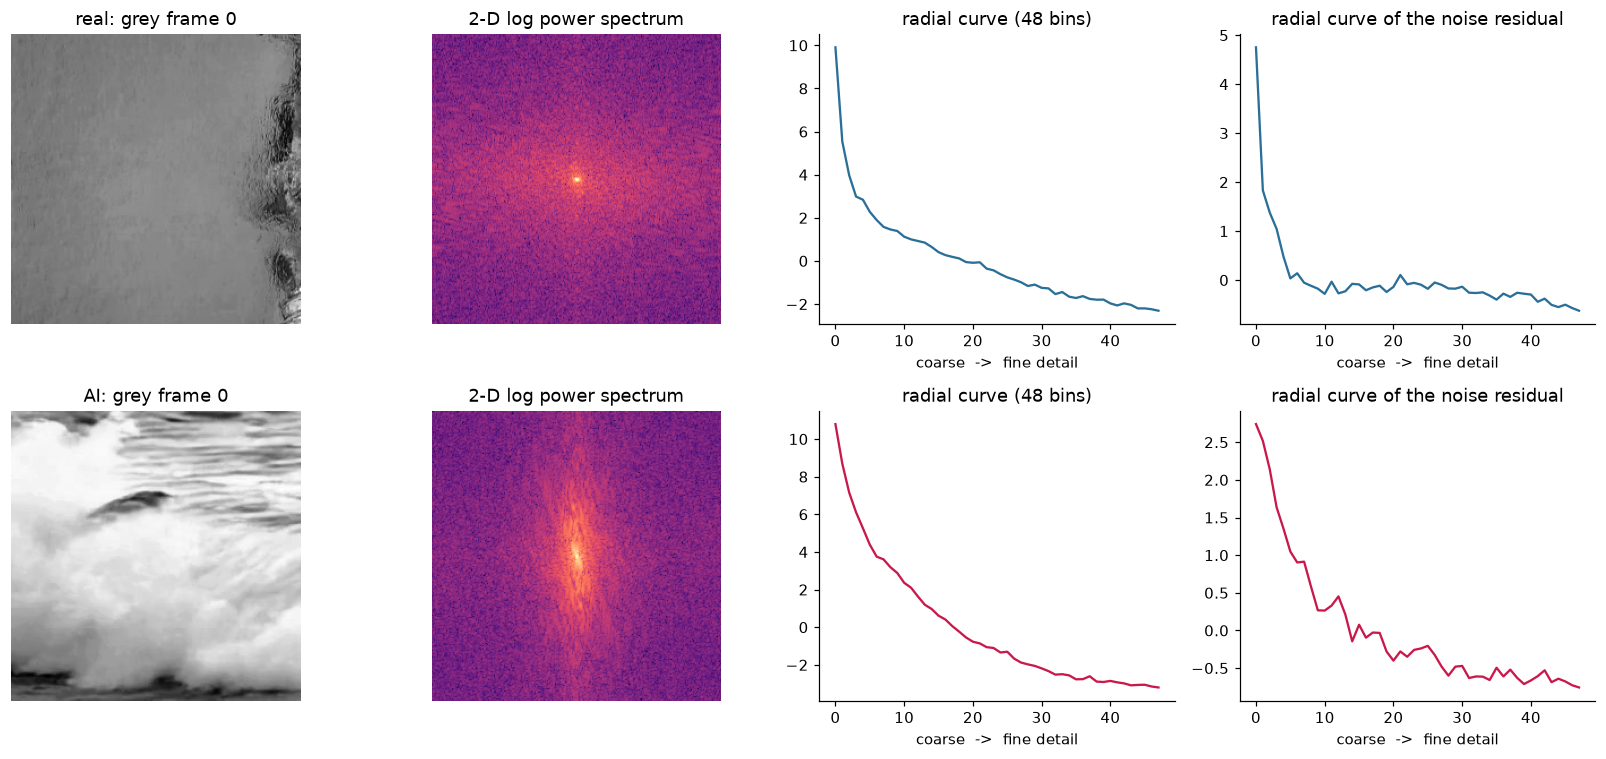

In [3]:
fig, ax = plt.subplots(2, 4, figsize=(15, 7))
curves = {}
for r, (tag, fr) in enumerate(frames.items()):
    g = to_luma(fr[0])
    spec = np.log(power_spectrum(g) + 1e-8)
    rad, res = radial_spectrum(g), radial_spectrum(residual(g))
    curves[tag] = (rad, res)
    ax[r, 0].imshow(g, cmap="gray"); ax[r, 0].set_title(f"{tag}: grey frame 0"); ax[r, 0].axis("off")
    ax[r, 1].imshow(spec, cmap="magma"); ax[r, 1].set_title("2-D log power spectrum"); ax[r, 1].axis("off")
    ax[r, 2].plot(rad, color=BLUE if tag == "real" else RED); ax[r, 2].set_title("radial curve (48 bins)")
    ax[r, 3].plot(res, color=BLUE if tag == "real" else RED); ax[r, 3].set_title("radial curve of the noise residual")
    for a in ax[r, 2:]:
        a.set_xlabel("coarse  ->  fine detail")
    ff = frame_features(g)
    print(f"{tag:5s} spectral slope {ff['slope']:+.2f}   energy beyond 75% of Nyquist {ff['hf_ratio_75']:.4f}")
plt.tight_layout(); plt.show()

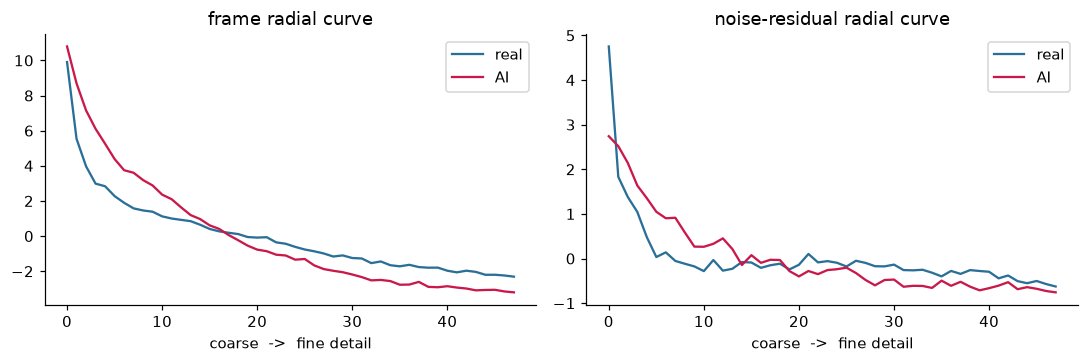

In [4]:
# Both clips on one axis: where do they differ?
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for tag, c in (("real", BLUE), ("AI", RED)):
    ax[0].plot(curves[tag][0], color=c, label=tag); ax[1].plot(curves[tag][1], color=c, label=tag)
ax[0].set_title("frame radial curve"); ax[1].set_title("noise-residual radial curve")
for a in ax:
    a.set_xlabel("coarse  ->  fine detail"); a.legend()
plt.tight_layout(); plt.show()

## 3. Change over time

The same curve is computed for all 14 frames. The distance between consecutive frames' curves is the **spectral drift**.
Camera footage and generated video fluctuate differently from frame to frame.

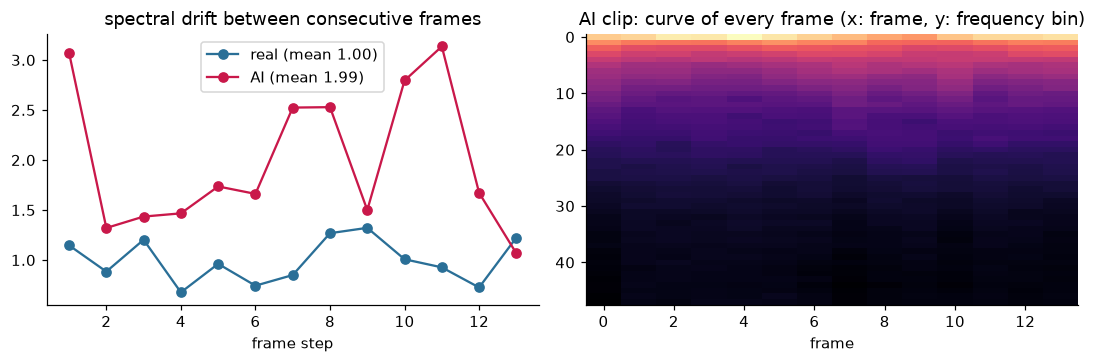

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for tag, c in (("real", BLUE), ("AI", RED)):
    rad = np.stack([radial_spectrum(to_luma(f)) for f in frames[tag]])        # 14 x 48
    drift = np.linalg.norm(np.diff(rad, axis=0), axis=1)                      # 13 steps
    ax[0].plot(range(1, 14), drift, "o-", color=c, label=f"{tag} (mean {drift.mean():.2f})")
    if tag == "AI":
        ax[1].imshow(rad.T, aspect="auto", cmap="magma")
ax[0].set_title("spectral drift between consecutive frames"); ax[0].set_xlabel("frame step"); ax[0].legend()
ax[1].set_title("AI clip: curve of every frame (x: frame, y: frequency bin)"); ax[1].set_xlabel("frame")
plt.tight_layout(); plt.show()

## 4. From curves to features

Per frame: 113 values (the two curves, slope, high-frequency shares, centroid, roll-off, DCT shares, 8 orientations).
Over the 14 frames the mean and standard deviation give **226** numbers (set A, fine detail). Drift statistics give **37** more
(set B, change over time): A + B = **263 frequency features**. The **74 pixel features** (brightness, contrast, colour) are the control.
Combined (fusion) = 337.

In [6]:
trace_id = FAKE_ID
path = CLIPS / f"{trace_id}.mp4"
feats, seq = clip_features(read_frames(path, N_FRAMES, FPS))
feats.update(clip_pixel_features(read_frames(path, N_FRAMES, FPS)))
freq = {k: v for k, v in feats.items() if k.startswith(("sp_", "drift_", "rt_"))}
pix = {k: v for k, v in feats.items() if k.startswith("px_")}
print(f"clip {trace_id}:  frequency {len(freq)}  (spatial {sum(k.startswith('sp_') for k in freq)}, "
      f"drift {sum(k.startswith('drift_') for k in freq)}, residual-temporal {sum(k.startswith('rt_') for k in freq)}),  "
      f"pixel {len(pix)},  fusion {len(freq) + len(pix)}")
print("CNN input (channels x frames x bins):", seq.shape)

# the same clip, real vs generated, for a few named features
both = pd.DataFrame({tag: clip_features(frames[tag])[0] for tag in frames})
print("\nA few features, real vs AI clip:")
print(both.loc[["drift_band_mid_mean", "rt_energy", "rt_lag1_corr", "sp_rad_32_std"]].round(3).to_string())

# is the live extraction identical to the stored features?
cached = D.clean_table()
row = cached[cached.clip_id == trace_id]
keys = list(freq)
print("\nlive vs stored features, max absolute difference:",
      f"{np.nanmax(np.abs(row[keys].to_numpy(float)[0] - np.array([freq[k] for k in keys]))):.2e}")

clip ltx_0001:  frequency 263  (spatial 226, drift 32, residual-temporal 5),  pixel 74,  fusion 337
CNN input (channels x frames x bins): (2, 14, 48)



A few features, real vs AI clip:
                      real     AI
drift_band_mid_mean  0.448  0.794
rt_energy           -8.157 -9.897
rt_lag1_corr        -0.049 -0.052
sp_rad_32_std        0.085  0.127

live vs stored features, max absolute difference: 0.00e+00


## 5. Trace one clip to its classification

The same 337 features are fed to each trained model. A model that sees only pixel features, only frequency features,
or both, gives the probability that the clip is AI-made (threshold 0.5).

In [7]:
FAM = L.FAMILIES      # {"pixel": "pixel", "frequency": "all", "fusion": "fusion"}
one = pd.DataFrame([feats])
rows = []
for fam, group in FAM.items():
    for mdl in ("lr", "lgbm", "mlp"):
        p = L.score(f"{mdl}_{group}", one)[0]
        rows.append({"model": mdl, "features": fam, "P(AI)": round(float(p), 3), "verdict": "AI" if p >= 0.5 else "real"})
cnn, stats = L.load_cnn()
from src.models.cnn import cnn_predict
pc = float(cnn_predict(cnn, stats, seq[None])[0])
rows.append({"model": "cnn", "features": "frequency (spectra)", "P(AI)": round(pc, 3), "verdict": "AI" if pc >= 0.5 else "real"})
truth = man[man.clip_id == trace_id].iloc[0]
print(f"clip {trace_id}: true label = {'AI' if truth.label == 1 else 'real'} ({truth.generator})\n")
print(pd.DataFrame(rows).to_string(index=False))

clip ltx_0001: true label = AI (ltx)

model            features  P(AI) verdict
   lr               pixel  0.983      AI
 lgbm               pixel  0.923      AI
  mlp               pixel  0.897      AI
   lr           frequency  0.627      AI
 lgbm           frequency  0.707      AI
  mlp           frequency  0.997      AI
   lr              fusion  0.793      AI
 lgbm              fusion  0.908      AI
  mlp              fusion  0.993      AI
  cnn frequency (spectra)  0.592      AI


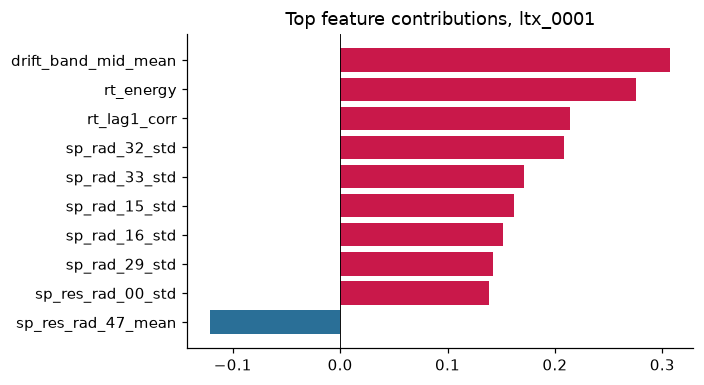

In [8]:
# Why? LightGBM's contribution of each feature (+ pushes towards "AI").
m, cols = L.load_model("lgbm_all")
X = np.nan_to_num(one[cols].to_numpy(np.float32))
contrib = m.predict(X, pred_contrib=True)[0][:-1]
top = np.argsort(-np.abs(contrib))[:10][::-1]
plt.figure(figsize=(6.5, 3.6))
plt.barh([cols[i] for i in top], contrib[top], color=[RED if contrib[i] > 0 else BLUE for i in top])
plt.axvline(0, color="k", lw=0.6); plt.title(f"Top feature contributions, {trace_id}"); plt.tight_layout(); plt.show()

## 6. Pixel-only vs frequency-only vs combined, on the same held-out clips

Now every one of the 267 held-out test clips goes through the same live extraction (about 30 s on 6 workers).
The models are not retrained or tuned: same files, same clips, three feature sets.

In [9]:
from concurrent.futures import ProcessPoolExecutor
te = test.reset_index(drop=True)
with ProcessPoolExecutor(6) as ex:
    res = list(ex.map(L._extract, [str(CLIPS / f"{c}.mp4") for c in te.clip_id], chunksize=4))
F = pd.DataFrame([r[0] for r in res]); S = np.stack([r[1] for r in res])
y = te.label.to_numpy().astype(int)
print(f"extracted {len(F)} clips x {F.shape[1]} features live;  real {int((y == 0).sum())}, AI {int((y == 1).sum())}")

extracted 267 clips x 337 features live;  real 65, AI 202


In [10]:
scores = {f"{mdl}|{fam}": L.score(f"{mdl}_{group}", F) for fam, group in FAM.items() for mdl in ("lr", "lgbm", "mlp")}
scores["cnn|frequency"] = cnn_predict(cnn, stats, S)

real = (te.generator == "real").to_numpy()
sets = {"seen generators": ~te.generator.isin(UNSEEN).to_numpy(),
        "ModelScope (unseen)": real | (te.generator == "modelscope").to_numpy(),
        "Wan2.1 (unseen)": real | (te.generator == "wan").to_numpy()}

rows = []
for sname, mask in sets.items():
    bs = L.boot(y[mask], {k: v[mask] for k, v in scores.items()})
    for k, v in scores.items():
        mdl, fam = k.split("|")
        lo, hi = np.percentile(bs[k], [2.5, 97.5])
        rows.append({"set": sname, "n": int(mask.sum()), "model": mdl, "features": fam,
                     "auroc": roc_auc_score(y[mask], v[mask]), "lo": lo, "hi": hi})
R = pd.DataFrame(rows)
R["AUROC [95% CI]"] = R.apply(lambda r: f"{r.auroc:.3f} [{r.lo:.2f}, {r.hi:.2f}]", axis=1)
for sname in sets:
    sub = R[R.set == sname]
    print(f"\n{sname}  (n = {sub.n.iloc[0]} clips)")
    print(sub.pivot(index="model", columns="features", values="AUROC [95% CI]")
             [["pixel", "frequency", "fusion"]].fillna("-").to_string())


seen generators  (n = 111 clips)
features               pixel           frequency              fusion
model                                                               
cnn                        -  0.941 [0.90, 0.98]                   -
lgbm      0.904 [0.85, 0.95]  0.920 [0.87, 0.96]  0.943 [0.90, 0.98]
lr        0.880 [0.81, 0.93]  0.943 [0.89, 0.98]  0.950 [0.91, 0.98]
mlp       0.881 [0.82, 0.94]  0.960 [0.92, 0.99]  0.976 [0.95, 0.99]

ModelScope (unseen)  (n = 164 clips)
features               pixel           frequency              fusion
model                                                               
cnn                        -  0.753 [0.68, 0.82]                   -
lgbm      0.574 [0.48, 0.67]  0.691 [0.61, 0.77]  0.691 [0.61, 0.78]
lr        0.657 [0.56, 0.74]  0.753 [0.68, 0.83]  0.770 [0.69, 0.84]
mlp       0.611 [0.51, 0.69]  0.792 [0.72, 0.86]  0.738 [0.66, 0.82]

Wan2.1 (unseen)  (n = 122 clips)
features               pixel           frequency              fusi

In [11]:
# Is the difference real or luck? Paired bootstrap on the same clips (seen set, MLP).
mask = sets["seen generators"]
bs = L.boot(y[mask], {k: v[mask] for k, v in scores.items() if k.startswith("mlp")})
for a, b in (("frequency", "pixel"), ("fusion", "frequency"), ("fusion", "pixel")):
    d = bs[f"mlp|{a}"] - bs[f"mlp|{b}"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"{a:>9s} minus {b:<9s}: {d.mean():+.3f}   95% interval [{lo:+.3f}, {hi:+.3f}]   "
          + ("excludes 0" if lo > 0 or hi < 0 else "includes 0 (not significant)"))

frequency minus pixel    : +0.075   95% interval [+0.020, +0.145]   excludes 0
   fusion minus frequency: +0.017   95% interval [-0.006, +0.046]   includes 0 (not significant)
   fusion minus pixel    : +0.092   95% interval [+0.045, +0.147]   excludes 0


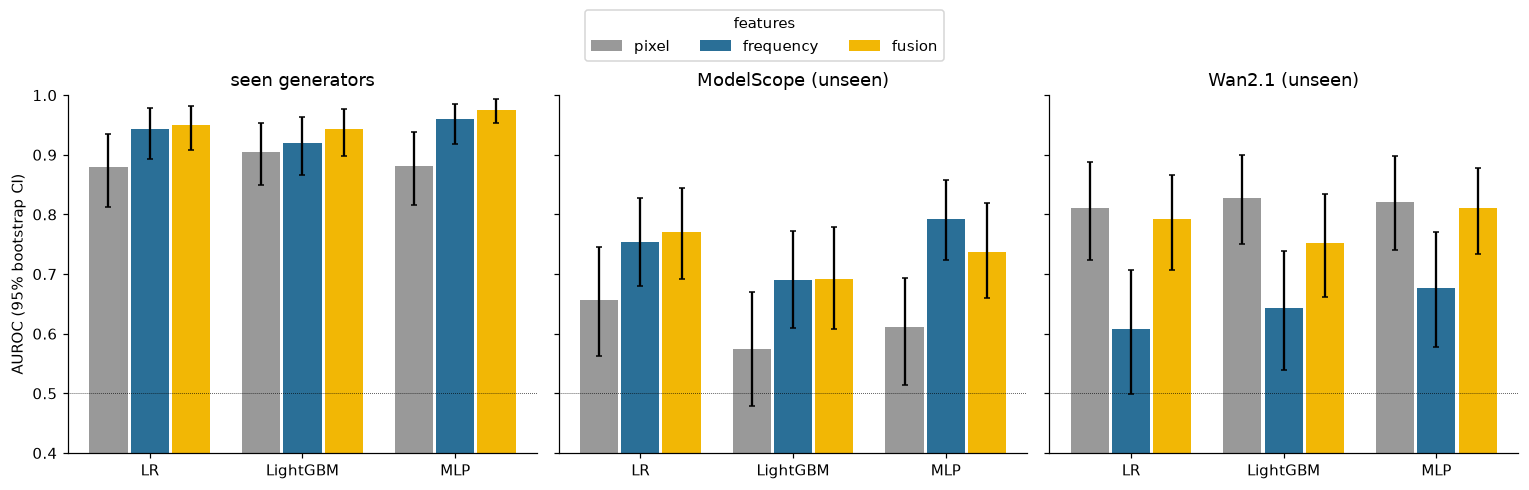

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
cols3 = {"pixel": "#999999", "frequency": BLUE, "fusion": "#f2b705"}
for a, sname in zip(ax, sets):
    sub = R[(R.set == sname) & (R.model != "cnn")]
    for i, mdl in enumerate(("lr", "lgbm", "mlp")):
        for j, fam in enumerate(("pixel", "frequency", "fusion")):
            r = sub[(sub.model == mdl) & (sub.features == fam)].iloc[0]
            a.bar(i + (j - 1) * 0.27, r.auroc, 0.25, yerr=[[r.auroc - r.lo], [r.hi - r.auroc]], capsize=2,
                  color=cols3[fam], label=fam if i == 0 else None)
    a.set_xticks(range(3), ["LR", "LightGBM", "MLP"]); a.set_title(sname); a.set_ylim(0.4, 1.0)
    a.axhline(0.5, color="k", lw=0.5, ls=":")
ax[0].set_ylabel("AUROC (95% bootstrap CI)")
fig.legend(*ax[0].get_legend_handles_labels(), title="features", loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
os.makedirs("demo_output", exist_ok=True)
plt.savefig("demo_output/notebook_comparison.png", dpi=130); plt.show()

## 7. Reproducibility check

The live AUROCs on the seen test set against the numbers stored in `results_crop/test_metrics.csv`
(produced earlier by the training pipeline, not by this notebook).

In [13]:
stored = pd.read_csv(RESULTS / "test_metrics.csv")
stored = stored[stored.set == "seen_test"].set_index("model").auroc
rows = []
for mdl in ("lr", "lgbm", "mlp"):
    for fam, group in FAM.items():
        live = R[(R.set == "seen generators") & (R.model == mdl) & (R.features == fam)].auroc.iloc[0]
        rows.append({"model": f"{mdl}_{group}", "live": round(live, 3), "stored": round(stored[f"{mdl}_{group}"], 3)})
T = pd.DataFrame(rows); T["diff"] = (T.live - T.stored).round(3)
print(T.to_string(index=False))
worst = (T.live - T.stored).abs().max()
print(f"\nlargest difference {worst:.4f} ->", "matches the stored results." if worst < 0.005 else "CHECK: differs.")

      model  live  stored  diff
   lr_pixel 0.880   0.880   0.0
     lr_all 0.943   0.943   0.0
  lr_fusion 0.950   0.950   0.0
 lgbm_pixel 0.904   0.904   0.0
   lgbm_all 0.920   0.920   0.0
lgbm_fusion 0.943   0.943   0.0
  mlp_pixel 0.881   0.881   0.0
    mlp_all 0.960   0.960   0.0
 mlp_fusion 0.976   0.976   0.0

largest difference 0.0000 -> matches the stored results.
